# 02 · Customer Retention and Feature Transforms

**Project:** AI Retail Analytics Copilot
**Input:** `master_orders.csv`, the clean order-level table built in notebook 01 (96,154 delivered orders, January 2017 – August 2018)

**Goal of this notebook:** measure how often customers come back, find out whether a bad first experience stops them, define the target for the churn model, and decide which numeric features need a log transform before modelling.

### Contents
1. Setup
2. How many customers come back?
3. Cohort retention
4. Does a bad first experience stop customers returning?
5. Defining the churn target
6. Skewed features and log transforms
7. Key insights

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 30)
plt.rcParams['figure.figsize'] = (12, 4)

try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_PATH = '/content/drive/MyDrive/Olist/'
except ImportError:
    DATA_PATH = '../data/'

master = pd.read_csv(DATA_PATH + 'master_orders.csv', parse_dates=['purchase_date'])
master['purchase_month'] = master['purchase_date'].dt.to_period('M')
master['purchase_day'] = master['purchase_date'].dt.normalize()     # date without the time

print(f"Orders: {len(master):,} | Real customers: {master['customer_person_id'].nunique():,}")

Mounted at /content/drive
Orders: 96,154 | Real customers: 93,053


## 2. How many customers come back?

In [2]:
orders_per_person = master.groupby('customer_person_id')['order_id'].count()
orders_per_person.value_counts().sort_index().to_frame('customers').T

order_id,1,2,3,4,5,6,7,9,15
customers,90269,2558,179,28,9,5,3,1,1


In [3]:
# A second order on the SAME day is one shopping trip split into two orders, not a return
first_day = master.groupby('customer_person_id')['purchase_day'].min()
master['first_day'] = master['customer_person_id'].map(first_day)

same_day_extra_orders = (master['purchase_day'] == master['first_day']) & \
                        master.duplicated(['customer_person_id', 'purchase_day'])
returning_customers = master.loc[master['purchase_day'] > master['first_day'], 'customer_person_id'].unique()
total_customers = master['customer_person_id'].nunique()

print(f"Customers with more than one order:            {(orders_per_person > 1).sum():,} ({(orders_per_person > 1).mean():.2%})")
print(f"Extra orders placed on the first shopping day:  {same_day_extra_orders.sum():,}")
print(f"Customers who came back on a later day:         {len(returning_customers):,} ({len(returning_customers) / total_customers:.2%})")

Customers with more than one order:            2,784 (2.99%)
Extra orders placed on the first shopping day:  855
Customers who came back on a later day:         2,002 (2.15%)


**Findings:** 2,784 customers (2.99%) have more than one order, but **855 extra orders were placed on the same day as the first**, as part of the same shopping trip. Counting only real returns (an order on a later day), **just 2,002 of 93,053 customers (2.15%) ever came back.**

## 3. Cohort retention

A **cohort** is the group of customers whose first order was in the same month. For each cohort, the table shows the share of customers who ordered again 1, 2, 3… months later.

In [4]:
master['cohort_month'] = master['customer_person_id'].map(master.groupby('customer_person_id')['purchase_month'].min())
master['months_since_first'] = (master['purchase_month'] - master['cohort_month']).apply(lambda gap: gap.n)

active_customers = (master.groupby(['cohort_month', 'months_since_first'])['customer_person_id']
                          .nunique()
                          .unstack(fill_value=0))
retention = active_customers.div(active_customers[0], axis=0) * 100    # % of each cohort's starting size
retention.iloc[:, :7].round(1)

months_since_first,0,1,2,3,4,5,6
cohort_month,,,,,,,
2017-01,100.0,0.3,0.3,0.1,0.4,0.1,0.4
2017-02,100.0,0.2,0.3,0.1,0.4,0.1,0.2
2017-03,100.0,0.4,0.4,0.4,0.4,0.2,0.2
2017-04,100.0,0.6,0.2,0.2,0.3,0.3,0.4
2017-05,100.0,0.5,0.5,0.3,0.3,0.3,0.4
2017-06,100.0,0.5,0.4,0.4,0.3,0.4,0.4
2017-07,100.0,0.5,0.3,0.2,0.3,0.2,0.3
2017-08,100.0,0.7,0.3,0.3,0.3,0.5,0.3
2017-09,100.0,0.7,0.5,0.3,0.4,0.2,0.2


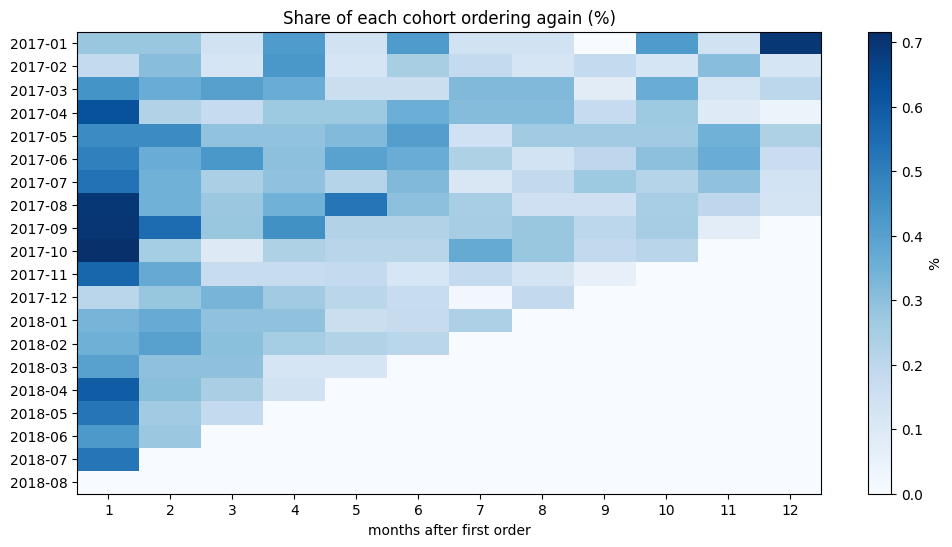

Average share ordering again 1 month later: 0.45%


In [5]:
# Heatmap of months 1–12 (month 0 is always 100%, so it is left out)
months_shown = retention.loc[:, 1:12]
fig, ax = plt.subplots(figsize=(12, 6))
image = ax.imshow(months_shown.values, cmap='Blues', aspect='auto', vmin=0)
ax.set_xticks(range(months_shown.shape[1]), months_shown.columns)
ax.set_yticks(range(months_shown.shape[0]), months_shown.index.astype(str))
ax.set_xlabel('months after first order')
ax.set_title('Share of each cohort ordering again (%)')
fig.colorbar(image, ax=ax, label='%')
plt.show()

print(f"Average share ordering again 1 month later: {retention[1].mean():.2f}%")

**Findings:** in every cohort, only 0.1–0.7% of customers order again in any later month (0.45% one month later on average). Recent cohorts show 0% in later months only because the data ends in August 2018: those customers had no time to return. A zero here means "not observable yet", not "didn't happen".

## 4. Does a bad first experience stop customers returning?

In [6]:
first_orders = master.sort_values('purchase_date').drop_duplicates('customer_person_id').copy()
first_orders['came_back'] = first_orders['customer_person_id'].isin(returning_customers).astype(int)

comparison = pd.DataFrame({
    'bad review vs good review': first_orders.groupby('got_bad_review')['came_back'].mean().values,
    'late vs on time': first_orders.groupby('was_late')['came_back'].mean().values,
}, index=['good / on time', 'bad / late']) * 100
comparison.round(2)

,bad review vs good review,late vs on time
good / on time,2.22,2.19
bad / late,1.71,1.60


**Findings:** a bad first experience lowers the return rate by about a quarter: 1.71% after a bad review vs 2.22% after a good one, and 1.60% after a late delivery vs 2.19% after an on-time one. But even happy customers almost never return, so bad experiences are not the main reason for low retention. A likely reason (a hypothesis, not proven here): customers buy through large marketplaces and may not know they bought from Olist, so there is no brand loyalty to build on.

## 5. Defining the churn target

**Target:** did the customer order again on a *later day* within 180 days of their first order?
Only customers whose first order was before 1 March 2018 are included, so everyone had at least 180 days of data in which to return.

In [7]:
later_orders = master[master['purchase_day'] > master['first_day']]
next_order_day = later_orders.groupby('customer_person_id')['purchase_day'].min()

first_orders['days_to_next_order'] = (first_orders['customer_person_id'].map(next_order_day)
                                      - first_orders['purchase_day']).dt.days
first_orders['returned_within_180_days'] = (first_orders['days_to_next_order'] <= 180).astype(int)

churn_base = first_orders[first_orders['purchase_date'] < '2018-03-01']
print(f"Customers in the churn base: {len(churn_base):,}")
print(f"Returned within 180 days:    {churn_base['returned_within_180_days'].sum():,} "
      f"({churn_base['returned_within_180_days'].mean():.2%})")
print(f"Median days to the next order (those who returned): {churn_base['days_to_next_order'].median():.0f}")

Customers in the churn base: 55,215
Returned within 180 days:    1,096 (1.98%)
Median days to the next order (those who returned): 106


**Findings:** 55,215 customers are in the churn base, and only **1,096 (1.98%) returned within 180 days**; customers who returned at any point took a median of 106 days. This is a **highly imbalanced** target (about 1 positive in 50): a model that predicts "never returns" for everyone would be 98% accurate and completely useless. The churn model will therefore be judged on precision, recall and PR-AUC, and modest results are expected. The bad-review model remains the main model.

## 6. Skewed features and log transforms

**Skewness** measures how lopsided a column is: around 0 is balanced, above 1 is strongly skewed. A **log transform** (`log(1 + x)`) shrinks large values much more than small ones, so a few very expensive orders no longer dominate a model. The `+1` keeps zero values (e.g. free shipping) valid.

In [8]:
numeric_columns = ['items_price', 'shipping_cost', 'distance_seller_to_customer_km',
                   'days_to_deliver', 'days_promised']

pd.DataFrame({
    'skew before': master[numeric_columns].skew(),
    'skew after log': np.log1p(master[numeric_columns]).skew(),
}).round(2)

,skew before,skew after log
items_price,9.90,0.29
shipping_cost,12.30,0.45
distance_seller_to_customer_km,1.66,-1.05
days_to_deliver,3.03,-0.10
days_promised,0.83,-1.01


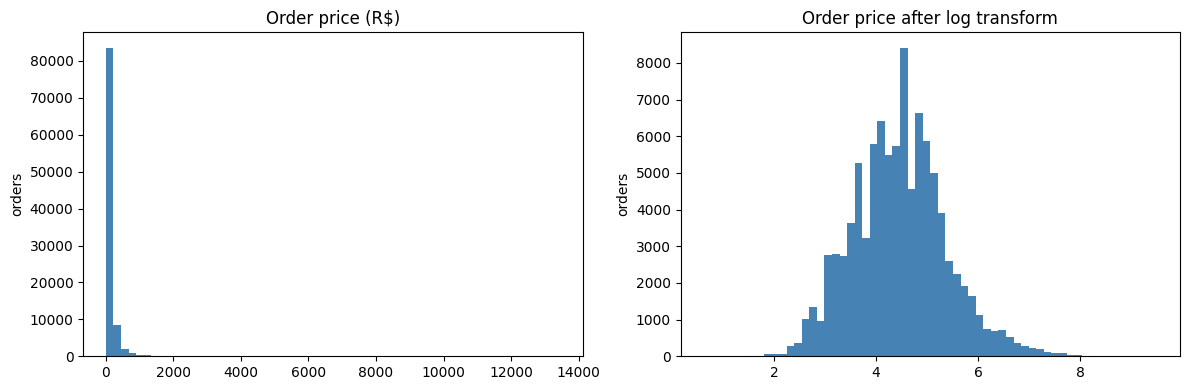

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
master['items_price'].plot(kind='hist', bins=60, ax=axes[0], color='steelblue', title='Order price (R$)')
np.log1p(master['items_price']).plot(kind='hist', bins=60, ax=axes[1], color='steelblue', title='Order price after log transform')
for ax in axes:
    ax.set_ylabel('orders')
plt.tight_layout()
plt.show()

**Decisions:**

| Feature | Skew before → after log | Use log? |
| --- | --- | --- |
| items_price | 9.90 → 0.29 | Yes |
| shipping_cost | 12.30 → 0.45 | Yes |
| days_to_deliver | 3.03 → −0.10 | Yes |
| distance_seller_to_customer_km | 1.66 → −1.05 | No: over-corrects into the opposite skew |
| days_promised | 0.83 → −1.01 | No: already fairly balanced |

Check skewness before *and* after: a log transform is not always an improvement. Tree-based models (random forest, XGBoost) don't need these transforms; they matter for linear models and K-Means clustering.

## 7. Key insights

1. **Only 2.15% of customers ever return**, and every monthly cohort keeps under 1% of its customers in any later month.
2. **Same-day repeat orders (855) are split shopping trips** and must not be counted as loyalty.
3. **A bad first experience reduces returns by about a quarter**, but it is not the main cause of low retention.
4. **Churn target defined:** return within 180 days (1.98% positive), judged on precision, recall and PR-AUC.
5. **Price, shipping cost and delivery days will be log-transformed** for linear models and clustering.

**Next:** notebook 03, customer segmentation (RFM and K-Means).